# Rolling windows, smoothing, lags and leads

In [1]:
# Setup: install the toolkit when running on Google Colab, and a plotting style
import sys

if "google.colab" in sys.modules:
    %pip install -q "econts[book] @ git+https://github.com/hmorao95/econ-time-series-manual"

import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 3.6), "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from econts import load

payems = load("PAYEMS").asfreq("MS")
cpi = load("CPIAUCSL").asfreq("MS")
brent = load("DCOILBRENTEU").dropna()

## Moving averages

In [3]:
jobs = payems.diff()  # monthly change, thousands
ma = pd.DataFrame(
    {
        "monthly change": jobs,
        "3m trailing": jobs.rolling(3).mean(),
        "12m trailing": jobs.rolling(12).mean(),
        "13m centered": jobs.rolling(13, center=True).mean(),
    }
)
print(ma.loc["2025-06":].round(0))

            monthly change  3m trailing  12m trailing  13m centered
date                                                               
2025-06-01           -20.0         34.0          65.0          27.0
2025-07-01            64.0         19.0          66.0          21.0
2025-08-01           -70.0         -9.0          60.0          13.0
2025-09-01            76.0         23.0          53.0          26.0
2025-10-01          -140.0        -45.0          39.0          32.0
2025-11-01            41.0         -8.0          31.0          29.0
2025-12-01           -17.0        -39.0          10.0          30.0
2026-01-01           160.0         61.0          27.0          31.0
2026-02-01          -156.0         -4.0          10.0          36.0
2026-03-01           214.0         73.0          23.0          44.0
2026-04-01           148.0         69.0          26.0           NaN
2026-05-01            63.0        142.0          30.0           NaN
2026-06-01            31.0         81.0         

The centered average has no value for the last six months: it needs data
that do not exist yet. That is the end-point problem of chapter 6 again.

## Exponential smoothing

An exponentially weighted moving average puts weight $\alpha (1-\alpha)^k$
on the observation $k$ periods ago. Parameterize it by `halflife` (periods
for the weight to halve), `span` or `alpha`.

In [4]:
ewma = jobs.ewm(halflife=3).mean()
print(ewma.tail(3).round(0))

date
2026-07-01    43.0
2026-08-01    62.0
2026-09-01    55.0
Freq: MS, Name: PAYEMS, dtype: float64


## 3m/3m annualized growth

The growth of the last three months' average over the previous three
months, annualized. A standard way to read noisy monthly inflation:

Text(0.5, 1.0, 'US CPI inflation, three ways (%)')

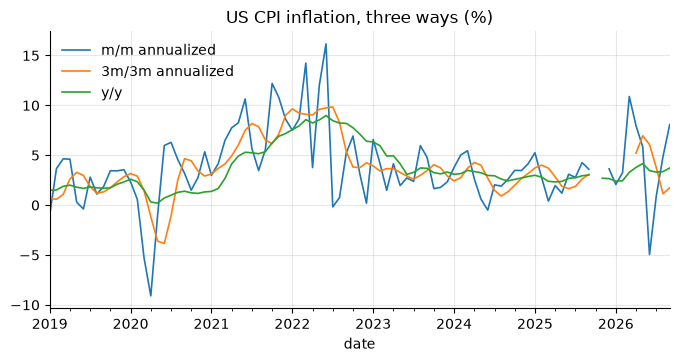

In [5]:
avg3 = cpi.rolling(3).mean()
infl = pd.DataFrame(
    {
        "m/m annualized": 100 * ((cpi / cpi.shift(1)) ** 12 - 1),
        "3m/3m annualized": 100 * ((avg3 / avg3.shift(3)) ** 4 - 1),
        "y/y": 100 * cpi.pct_change(12, fill_method=None),
    }
)
ax = infl.loc["2019":].plot(lw=1.2)
ax.set_title("US CPI inflation, three ways (%)")

3m/3m reacts faster than y/y and is much less noisy than m/m. The gaps in
late 2025 and 2026 are the missing October 2025 CPI (chapter 2): every
measure whose window touches that month is `NaN`.

## Rolling volatility and correlation

In [6]:
ret = 100 * np.log(brent).diff().dropna()  # daily log returns, %
vol = ret.rolling(21).std() * np.sqrt(252)  # annualized, 1-month window
print(vol.tail(3).round(1))

ret_m = 100 * np.log(load("DCOILBRENTEU").resample("MS").mean()).diff()
ip_m = 100 * np.log(load("INDPRO")).diff()
roll_corr = ret_m.rolling(60).corr(ip_m)  # 5-year rolling correlation
print(roll_corr.dropna().describe().round(2))

date
2026-10-30    79.7
2026-11-02    64.5
2026-11-03    60.0
Name: DCOILBRENTEU, dtype: float64
count    413.00
mean       0.18
std        0.24
min       -0.37
25%       -0.01
50%        0.16
75%        0.24
max        0.69
dtype: float64


Use `rolling("30D")` with a time-based window on irregular daily data: it
always covers 30 calendar days, however many observations fall inside.

In [7]:
vol_30d = ret.rolling("30D", min_periods=15).std() * np.sqrt(252)

## Rolling regressions

`statsmodels` estimates a regression on every window efficiently. Example:
a rolling Okun's-law coefficient (change in unemployment on GDP growth).

In [8]:
import statsmodels.api as sm
from statsmodels.regression.rolling import RollingOLS

gdp = load("GDPC1").to_period("Q")
u = load("UNRATE").to_period("M").resample("Q").mean()
d = pd.DataFrame({"du": u.diff(), "g": 100 * np.log(gdp).diff()}).dropna()
d = d.loc[:"2019"]  # keep 2020 out of the windows
okun = RollingOLS(d["du"], sm.add_constant(d["g"]), window=40).fit()
print(okun.params["g"].dropna().iloc[::20].round(2))  # every 5 years

date
1958Q1   -0.32
1963Q1   -0.36
1968Q1   -0.27
1973Q1   -0.17
1978Q1   -0.27
1983Q1   -0.28
1988Q1   -0.28
1993Q1   -0.33
1998Q1   -0.23
2003Q1   -0.22
2008Q1   -0.19
2013Q1   -0.35
2018Q1   -0.39
Freq: Q-DEC, Name: g, dtype: float64


## Expanding windows

`expanding()` uses all data up to each date: the real-time version of a
full-sample statistic (e.g. a z-score that only uses the past).

In [9]:
growth = 100 * np.log(gdp).diff()
z_realtime = (growth - growth.expanding(40).mean()) / growth.expanding(40).std()

## Lags, leads and differences

In [10]:
df = pd.DataFrame({"y": gdp})
df["y_lag1"] = df["y"].shift(1)  # y(t-1)
df["y_lead1"] = df["y"].shift(-1)  # y(t+1)
df["d4"] = df["y"].diff(4)  # y(t) - y(t-4)
df["d_d4"] = df["y"].diff(4).diff()  # change in the 4-quarter difference
print(df.tail(3).round(0))

              y   y_lag1  y_lead1     d4   d_d4
date                                           
2026Q1  24274.0  24125.0  24408.0  624.0  140.0
2026Q2  24408.0  24274.0  24611.0  523.0 -101.0
2026Q3  24611.0  24408.0      NaN  498.0  -25.0


Many lags at once, for a distributed-lag or VAR design matrix (EMT `lagX`):

In [11]:
def lags(s: pd.Series, n: int) -> pd.DataFrame:
    return pd.concat({f"{s.name}_L{k}": s.shift(k) for k in range(1, n + 1)}, axis=1)


X = lags(growth.rename("g"), 4)
print(X.dropna().head(2).round(2))

        g_L1  g_L2  g_L3  g_L4
date                          
1948Q2  1.49  1.55 -0.21 -0.27
1948Q3  1.64  1.49  1.55 -0.21


```{admonition} In your projects
:class: tip
The same recipe is in the `econts` toolkit:

    # pandas: pd.concat({f'x_L{k}': x.shift(k) for k in range(1, n + 1)}, axis=1)
```

## Pitfalls

* `shift` moves by **rows**, not by time. On an irregular index, call
  `.asfreq()` first, or shift by time with `s.shift(freq="MS")`.
* A rolling statistic on data with `NaN` silently uses fewer observations
  when `min_periods` is lower than the window.
* Centered moving averages and two-sided filters leak future information
  into regressions: forecasts look great in-sample and fail out of sample.

## Summary

* **Trailing** windows (the default) use only the past: safe for real-time
  indicators and forecasting. **Centered** windows (`center=True`) use the
  future: fine for description, never as a regressor.
* Set `min_periods` deliberately; the default returns `NaN` until the
  window is full.
* Report noisy monthly data as **3-month averages** or **3m/3m
  annualized** growth.

## Exercises

1. Compute monthly changes in payroll employment (`PAYEMS`) and their 3-month trailing average for 2023 to the end of the sample. How many months show a fall in each, and which would you report in a briefing note?
2. Compute m/m annualized, 3m/3m annualized and y/y CPI inflation (`CPIAUCSL`) for 2021–2023. In which month does each peak, and how many months earlier does 3m/3m signal the turn than y/y?
3. Compute the annualized 21-day rolling volatility of daily Brent log returns (`DCOILBRENTEU`). Find its peak in 2008, 2020 and 2022, and compare the 2020 peak with the one from a `"30D"` time-based window.
4. Estimate a rolling 40-quarter Okun regression (change in unemployment on GDP growth) for Portugal (`LRHUTTTTPTQ156S`, `CLVMNACSCAB1GQPT`, 1995–2019) and compare its path with the US one in the chapter. Is the Portuguese coefficient more or less stable, and why might labour-market institutions matter?